### Working with numerical data

The "data" in Data Analysis typically refers to numerical data, e.g., stock prices, sales figures, sensor measurements, sports scores, database tables, etc. The Numpy library provides specialized data structures, functions, and other tools for numerical computing in Python. Let's work through an example to see why & how to use Numpy for working with numerical data.

Suppose we want to use climate data like the temperature, rainfall, and humidity to determine if a region is well suited for growing apples. A simple approach for doing this would be to formulate the relationship between the annual yield of apples (tons per hectare) and the climatic conditions like the average temperature (in degrees Fahrenheit), rainfall (in millimeters) & average relative humidity (in percentage) as a linear equation.

yield_of_apples = w1 * temperature + w2 * rainfall + w3 * humidity

We're expressing the yield of apples as a weighted sum of the temperature, rainfall, and humidity. This equation is an approximation since the actual relationship may not necessarily be linear, and there may be other factors involved. But a simple linear model like this often works well in practice.

Based on some statical analysis of historical data, we might come up with reasonable values for the weights w1, w2, and w3. Here's an example set of values:

In [1]:
w1, w2, w3 = .3, .2, .5

In [2]:
kanto_temp = 73
kanto_rainfall = 67
kanto_humidity = 43

In [3]:
kanto_appleyeild = kanto_temp *w1 + kanto_rainfall *w2 + kanto_humidity * w3
kanto_appleyeild

56.8

In [4]:
print("The apple yield in Kanto is:", kanto_appleyeild)

The apple yield in Kanto is: 56.8


In [5]:
kanto = [73, 67, 43]
johto = [91, 88, 64]
hoenn = [87, 134, 58]
sinnoh = [102, 43, 37]
unova = [69, 96, 70]

In [6]:
weight = [w1, w2, w3]
weight

[0.3, 0.2, 0.5]

In [7]:
for item in zip(kanto, weight):
    print(item)

(73, 0.3)
(67, 0.2)
(43, 0.5)


In [8]:
def corp_yeild(region, weight):
    result = 0
    for x, w in zip(region, weight):
        result += x*w
    return result

In [9]:
corp_yeild(kanto, weight)

56.8

In [10]:
corp_yeild(johto, weight)

76.9

In [11]:
corp_yeild(hoenn, weight)

81.9

In [12]:
corp_yeild(sinnoh, weight)

57.699999999999996

In [13]:
corp_yeild(unova, weight)

74.9

In [14]:
result=0

for x, w in zip(kanto, weight):
    result += x*w
print(result)

56.8


### Going from Python lists to Numpy arrays
The calculation performed by the crop_yield (element-wise multiplication of two vectors and taking a sum of the results) is also called the dot product. Learn more about dot product here: https://www.khanacademy.org/math/linear-algebra/vectors-and-spaces/dot-cross-products/v/vector-dot-product-and-vector-length .

The Numpy library provides a built-in function to compute the dot product of two vectors. However, we must first convert the lists into Numpy arrays.

Let's install the Numpy library using the pip package manager.

In [15]:
import numpy as np

In [16]:
kanto = np.array([73, 67, 43])

In [17]:
kanto

array([73, 67, 43])

In [18]:
weights = np.array([.3, .2, .5])

In [19]:
type(weights)

numpy.ndarray

In [20]:
type(kanto)

numpy.ndarray

In [21]:
weights[0]


np.float64(0.3)

In [22]:
kanto[1]

np.int64(67)

### Operating on Numpy arrays
We can now compute the dot product of the two vectors using the np.dot function.

In [23]:
np.dot(kanto, weights)

np.float64(56.8)

In [24]:
help(np.dot)

Help on method descriptor dot in module numpy:

dot(a, b, out=None)
    dot(a, b, out=None)

    Dot product of two arrays. Specifically,

    - If both `a` and `b` are 1-D arrays, it is inner product of vectors
      (without complex conjugation).

    - If both `a` and `b` are 2-D arrays, it is matrix multiplication,
      but using :func:`matmul` or ``a @ b`` is preferred.

    - If either `a` or `b` is 0-D (scalar), it is equivalent to
      :func:`multiply` and using ``numpy.multiply(a, b)`` or ``a * b`` is
      preferred.

    - If `a` is an N-D array and `b` is a 1-D array, it is a sum product over
      the last axis of `a` and `b`.

    - If `a` is an N-D array and `b` is an M-D array (where ``M>=2``), it is a
      sum product over the last axis of `a` and the second-to-last axis of
      `b`::

        dot(a, b)[i,j,k,m] = sum(a[i,j,:] * b[k,:,m])

    It uses an optimized BLAS library when possible (see `numpy.linalg`).

    Parameters
    ----------
    a : array_like
   

In [25]:
np.dot(kanto, weights)

np.float64(56.8)

We can achieve the same result with low-level operations supported by Numpy arrays: performing an element-wise multiplication and calculating the resulting numbers' sum.

In [26]:
(kanto * weights)

array([21.9, 13.4, 21.5])

In [27]:
(kanto * weights).sum()

np.float64(56.8)

The * operator performs an element-wise multiplication of two arrays if they have the same size. The sum method calculates the sum of numbers in an array.

#### Benefits of using Numpy arrays
Numpy arrays offer the following benefits over Python lists for operating on numerical data:

Ease of use: You can write small, concise, and intuitive mathematical expressions like (kanto * weights).sum() rather than using loops & custom functions like crop_yield.

Performance: Numpy operations and functions are implemented internally in C++, which makes them much faster than using Python statements & loops that are interpreted at runtime

Here's a comparison of dot products performed using Python loops vs. Numpy arrays on two vectors with a million elements each.

In [28]:
arr1 = list(range(1000000))
arr2 = list(range(1000000, 2000000))

arr1_np = np.array(arr1)
arr2_np = np.array(arr2)

In [29]:
%%time
result = 0
for x1, x2 in zip(arr1, arr2):
    result += x1*x2
result

CPU times: total: 109 ms
Wall time: 92.4 ms


833332333333500000

In [30]:
%%time
np.dot(arr1_np, arr2_np)

CPU times: total: 0 ns
Wall time: 1.54 ms


np.int64(833332333333500000)

#### Multi-dimensional Numpy arrays

We can now go one step further and represent the climate data for all the regions using a single 2-dimensional Numpy array.

In [31]:
climate_data = np.array([[73, 67, 43], 
                         [91, 88, 64], 
                         [87, 134, 58], 
                         [102, 43, 37], 
                         [69, 96, 70]])

In [32]:
climate_data

array([[ 73,  67,  43],
       [ 91,  88,  64],
       [ 87, 134,  58],
       [102,  43,  37],
       [ 69,  96,  70]])

In [33]:
#2d array (matrix) with 5 rows and 3 columns
climate_data.shape

(5, 3)

In [34]:
weights

array([0.3, 0.2, 0.5])

In [35]:
weights.shape  #1d array with 3 elements

(3,)

In [36]:
#3D array
arr3 = np.array([
    [[11, 12, 13], [13, 14, 15]],
    [[15, 16, 17], [17, 18, 19.5]]])

In [37]:
arr3.shape  #3D array with 2 rows, 2 columns and 3 depth

(2, 2, 3)

If you've taken a linear algebra class in high school, you may recognize the above 2-d array as a matrix with five rows and three columns. Each row represents one region, and the columns represent temperature, rainfall, and humidity, respectively.

Numpy arrays can have any number of dimensions and different lengths along each dimension. We can inspect the length along each dimension using the .shape property of an array.

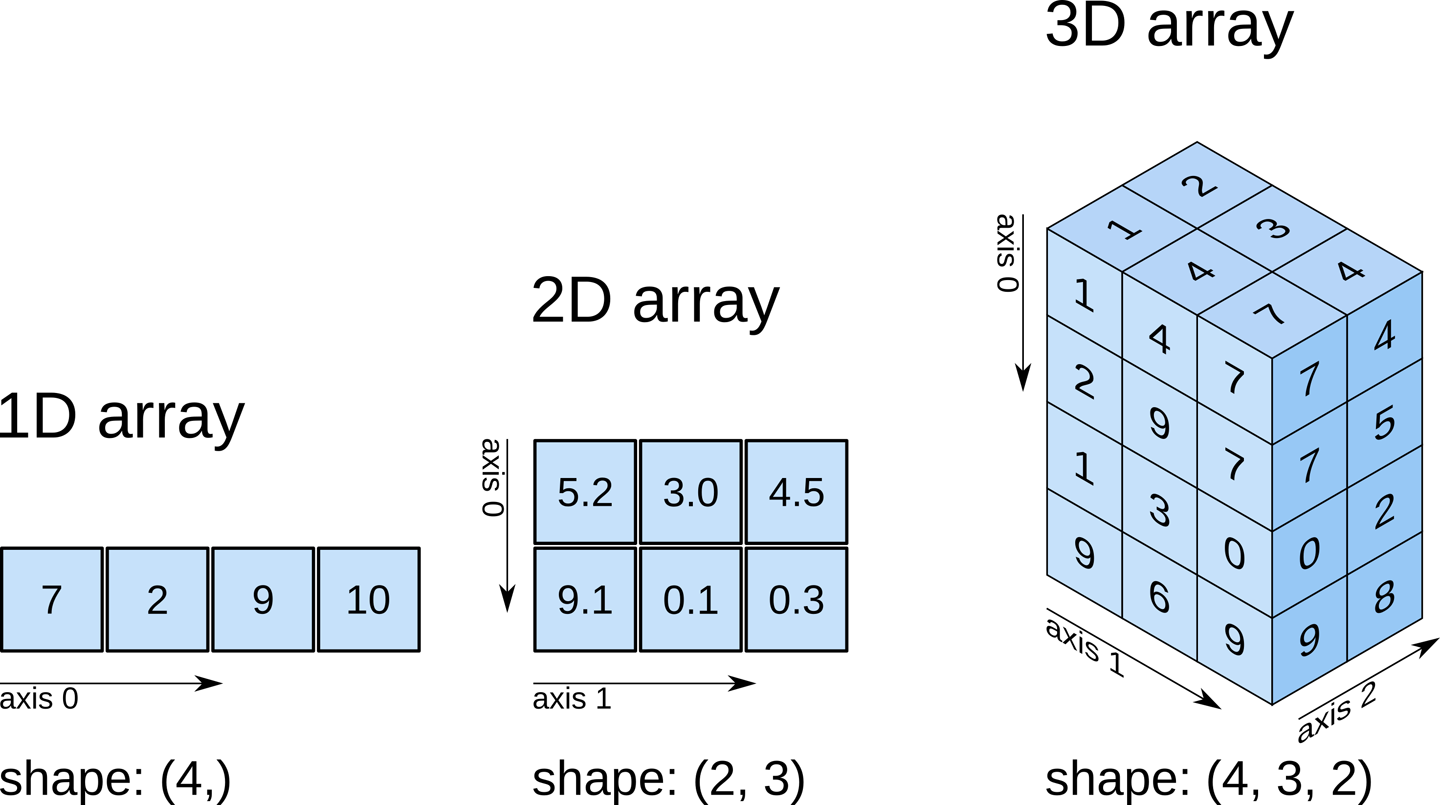

All the elements in a numpy array have the same data type. You can check the data type of an array using the .dtype property.

In [38]:
weights.dtype

dtype('float64')

In [39]:
climate_data.dtype

dtype('int64')

In [40]:
arr3 

array([[[11. , 12. , 13. ],
        [13. , 14. , 15. ]],

       [[15. , 16. , 17. ],
        [17. , 18. , 19.5]]])

In [41]:
arr3.dtype

dtype('float64')

We can now compute the predicted yields of apples in all the regions, using a single matrix multiplication between climate_data (a 5x3 matrix) and weights (a vector of length 3). Here's what it looks like visually:

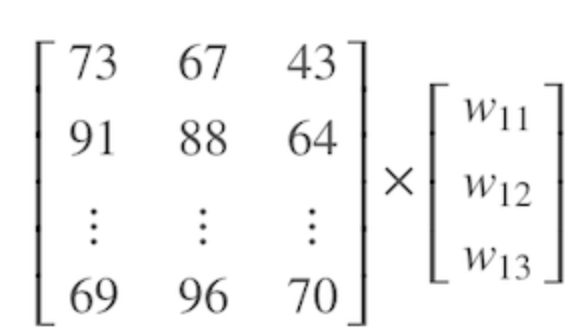

ou can learn about matrices and matrix multiplication by watching the first 3-4 videos of this playlist: https://www.youtube.com/watch?v=xyAuNHPsq-g&list=PLFD0EB975BA0CC1E0&index=1 .

We can use the np.matmul function or the @ operator to perform matrix multiplication.

In [42]:
np.matmul(climate_data, weights)

array([56.8, 76.9, 81.9, 57.7, 74.9])

In [43]:
climate_data @ weights

array([56.8, 76.9, 81.9, 57.7, 74.9])

### Working with CSV data files
Numpy also provides helper functions reading from & writing to files. Let's download a file climate.txt, which contains 10,000 climate measurements (temperature, rainfall & humidity) in the following format:

temperature,rainfall,humidity

25.00,76.00,99.00

39.00,65.00,70.00

59.00,45.00,77.00

84.00,63.00,38.00

66.00,50.00,52.00

41.00,94.00,77.00

91.00,57.00,96.00

49.00,96.00,99.00

67.00,20.00,28.00

...


This format of storing data is known as comma-separated values or CSV.

CSVs: A comma-separated values (CSV) file is a delimited text file that uses a comma to separate values. Each line of the file is a data record. Each record consists of one or more fields, separated by commas. A CSV file typically stores tabular data (numbers and text) in plain text, in which case each line will have the same number of fields. (Wikipedia)

To read this file into a numpy array, we can use the genfromtxt function.

In [211]:
import urllib.request
urllib.request.urlretrieve(
    'https://gist.github.com/BirajCoder/a4ffcb76fd6fb221d76ac2ee2b8584e9/raw/4054f90adfd361b7aa4255e99c2e874664094cea/climate.csv', 
    'climate.txt')

('climate.txt', <http.client.HTTPMessage at 0x2232bd96650>)

In [45]:
climate_data = np.genfromtxt('climate.txt', delimiter=',', skip_header=1)

In [46]:
climate_data

array([[25., 76., 99.],
       [39., 65., 70.],
       [59., 45., 77.],
       ...,
       [99., 62., 58.],
       [70., 71., 91.],
       [92., 39., 76.]], shape=(10000, 3))

In [47]:
climate_data.dtype

dtype('float64')

In [48]:
yeild = climate_data @ weights

In [49]:
yeild

array([72.2, 59.7, 65.2, ..., 71.1, 80.7, 73.4], shape=(10000,))

In [50]:
yeild.shape

(10000,)

In [51]:
help(np.genfromtxt)

Help on function genfromtxt in module numpy:

genfromtxt(
    fname,
    dtype=<class 'float'>,
    comments='#',
    delimiter=None,
    skip_header=0,
    skip_footer=0,
    converters=None,
    missing_values=None,
    filling_values=None,
    usecols=None,
    names=None,
    excludelist=None,
    deletechars=" !#$%&'()*+,-./:;<=>?@[\\]^{|}~",
    replace_space='_',
    autostrip=False,
    case_sensitive=True,
    defaultfmt='f%i',
    unpack=None,
    usemask=False,
    loose=True,
    invalid_raise=True,
    max_rows=None,
    encoding=None,
    *,
    ndmin=0,
    like=None
)
    Load data from a text file, with missing values handled as specified.

    Each line past the first `skip_header` lines is split at the `delimiter`
    character, and characters following the `comments` character are discarded.

    Parameters
    ----------
    fname : file, str, pathlib.Path, list of str, generator
        File, filename, list, or generator to read.  If the filename
        extension

In [52]:
climate_result = np.concatenate((climate_data, yeild.reshape(10000, 1)), axis=1)

In [53]:
help(np.concatenate)

Help on method descriptor concatenate in module numpy:

concatenate(arrays, /, axis=0, out=None, *, dtype=None, casting='same_kind')
    Join a sequence of arrays along an existing axis.

    .. versionadded:: 2.0
        ``numpy.concat`` added as a shorthand for ``numpy.concatenate``.

    Parameters
    ----------
    a1, a2, ... : sequence of array_like
        The arrays must have the same shape, except in the dimension
        corresponding to `axis` (the first, by default).
    axis : int, optional
        The axis along which the arrays will be joined.  If axis is None,
        arrays are flattened before use.  Default is 0.
    out : ndarray, optional
        If provided, the destination to place the result. The shape must be
        correct, matching that of what concatenate would have returned if no
        out argument were specified.
    dtype : str or dtype
        If provided, the destination array will have this dtype. Cannot be
        provided together with `out`.

   

In [54]:
climate_result

array([[25. , 76. , 99. , 72.2],
       [39. , 65. , 70. , 59.7],
       [59. , 45. , 77. , 65.2],
       ...,
       [99. , 62. , 58. , 71.1],
       [70. , 71. , 91. , 80.7],
       [92. , 39. , 76. , 73.4]], shape=(10000, 4))

In [55]:
weights1 = np.append(weights, .9)
weights2 = np.append(weights, .7)
weights3 = weights1 @ weights2

climate_result @ weights2

array([122.74, 101.49, 110.84, ..., 120.87, 137.19, 124.78],
      shape=(10000,))

In [57]:
climate_result

array([[25. , 76. , 99. , 72.2],
       [39. , 65. , 70. , 59.7],
       [59. , 45. , 77. , 65.2],
       ...,
       [99. , 62. , 58. , 71.1],
       [70. , 71. , 91. , 80.7],
       [92. , 39. , 76. , 73.4]], shape=(10000, 4))

There are a couple of subtleties here:

Since we wish to add new columns, we pass the argument axis=1 to np.concatenate. The axis argument specifies the dimension for concatenation.

The arrays should have the same number of dimensions, and the same length along each except the dimension used for concatenation. We use the np.reshape function to change the shape of yields from (10000,) to (10000,1).

Here's a visual explanation of np.concatenate along axis=1 (can you guess what axis=0 results in?):

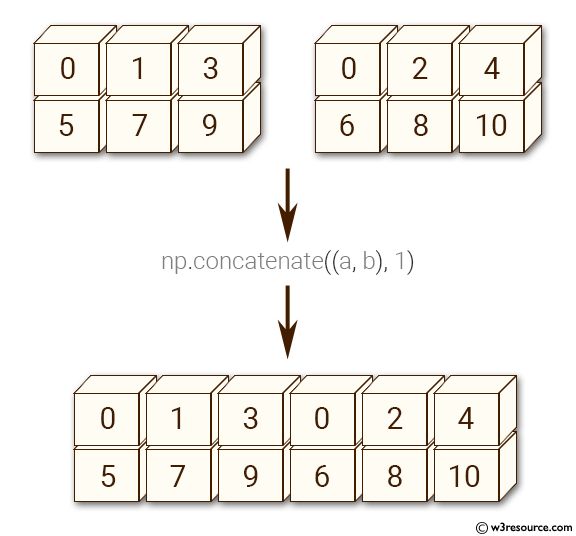

The best way to understand what a Numpy function does is to experiment with it and read the documentation to learn about its arguments & return values. Use the cells below to experiment with np.concatenate and np.reshape.

In [58]:
weights.shape

(3,)

In [59]:
weights.reshape(3, 1)

array([[0.3],
       [0.2],
       [0.5]])

In [63]:
yeild2 =climate_data @ weights.reshape(3, 1)

In [64]:
yeild2

array([[72.2],
       [59.7],
       [65.2],
       ...,
       [71.1],
       [80.7],
       [73.4]], shape=(10000, 1))

In [66]:
newresult = np.concatenate((climate_data, yeild2), axis=1)

In [67]:
newresult

array([[25. , 76. , 99. , 72.2],
       [39. , 65. , 70. , 59.7],
       [59. , 45. , 77. , 65.2],
       ...,
       [99. , 62. , 58. , 71.1],
       [70. , 71. , 91. , 80.7],
       [92. , 39. , 76. , 73.4]], shape=(10000, 4))

There are a couple of subtleties here:

Since we wish to add new columns, we pass the argument axis=1 to np.concatenate. The axis argument specifies the dimension for concatenation.

The arrays should have the same number of dimensions, and the same length along each except the dimension used for concatenation. We use the np.reshape function to change the shape of yields from (10000,) to (10000,1).

Here's a visual explanation of np.concatenate along axis=1 (can you guess what axis=0

In [68]:
newresult

array([[25. , 76. , 99. , 72.2],
       [39. , 65. , 70. , 59.7],
       [59. , 45. , 77. , 65.2],
       ...,
       [99. , 62. , 58. , 71.1],
       [70. , 71. , 91. , 80.7],
       [92. , 39. , 76. , 73.4]], shape=(10000, 4))

In [84]:
np.savetxt('climate_result.txt',
           newresult,
           fmt= '%2f',
           delimiter=','
           header='temperature,rainfall,humidity,apple_yeild',
           comments=''
           )

SyntaxError: invalid syntax. Perhaps you forgot a comma? (2728497233.py, line 4)

In [72]:
help(np.savetxt)

Help on method descriptor savetxt in module numpy:

savetxt(
    fname,
    X,
    fmt='%.18e',
    delimiter=' ',
    newline='\n',
    header='',
    footer='',
    comments='# ',
    encoding=None
)
    Save an array to a text file.

    Parameters
    ----------
    fname : filename, file handle or pathlib.Path
        If the filename ends in ``.gz``, the file is automatically saved in
        compressed gzip format.  `loadtxt` understands gzipped files
        transparently.
    X : 1D or 2D array_like
        Data to be saved to a text file.
    fmt : str or sequence of strs, optional
        A single format (%10.5f), a sequence of formats, or a
        multi-format string, e.g. 'Iteration %d -- %10.5f', in which
        case `delimiter` is ignored. For complex `X`, the legal options
        for `fmt` are:

        * a single specifier, ``fmt='%.4e'``, resulting in numbers formatted
          like ``' (%s+%sj)' % (fmt, fmt)``
        * a full string specifying every real and imag


Numpy provides hundreds of functions for performing operations on arrays. Here are some commonly used functions:

Mathematics: np.sum, np.exp, np.round, arithemtic operators
Array manipulation: np.reshape, np.stack, np.concatenate, np.split
Linear Algebra: np.matmul, np.dot, np.transpose, np.eigvals
Statistics: np.mean, np.median, np.std, np.max
How to find the function you need? The easiest way to find the right function for a specific operation or use-case is to do a web search. For instance, searching for "How to join numpy arrays" leads to this tutorial on array concatenation.

You can find a full list of array functions here: https://numpy.org/doc/stable/reference/routines.html

In [85]:
help(np.split)

Help on method descriptor split in module numpy:

split(ary, indices_or_sections, axis=0)
    Split an array into multiple sub-arrays as views into `ary`.

    Parameters
    ----------
    ary : ndarray
        Array to be divided into sub-arrays.
    indices_or_sections : int or 1-D array
        If `indices_or_sections` is an integer, N, the array will be divided
        into N equal arrays along `axis`.  If such a split is not possible,
        an error is raised.

        If `indices_or_sections` is a 1-D array of sorted integers, the entries
        indicate where along `axis` the array is split.  For example,
        ``[2, 3]`` would, for ``axis=0``, result in

        - ary[:2]
        - ary[2:3]
        - ary[3:]

        If an index exceeds the dimension of the array along `axis`,
        an empty sub-array is returned correspondingly.
    axis : int, optional
        The axis along which to split, default is 0.

    Returns
    -------
    sub-arrays : list of ndarrays
     

In [88]:
arr = np.array([1, 2, 3, 4])
narr= np.exp(arr)
print(narr)

[ 2.71828183  7.3890561  20.08553692 54.59815003]


In [91]:
np.round(narr, decimals=2)
help(np.round)

Help on method descriptor round in module numpy:

round(a, decimals=0, out=None)
    Evenly round to the given number of decimals.

    Parameters
    ----------
    a : array_like
        Input data.
    decimals : int, optional
        Number of decimal places to round to (default: 0).  If
        decimals is negative, it specifies the number of positions to
        the left of the decimal point.
    out : ndarray, optional
        Alternative output array in which to place the result. It must have
        the same shape as the expected output, but the type of the output
        values will be cast if necessary. See :ref:`ufuncs-output-type`
        for more details.

    Returns
    -------
    rounded_array : ndarray
        An array of the same type as `a`, containing the rounded values.
        Unless `out` was specified, a new array is created.  A reference to
        the result is returned.

        The real and imaginary parts of complex numbers are rounded
        separately.

### Arithmetic operations, broadcasting and comparison
"""Numpy arrays support arithmetic operators like +, -, *, etc. You can perform an arithmetic operation with a single number (also called scalar) or with another array of the same shape. Operators make it easy to write mathematical expressions with multi-dimensional arrays."""

In [92]:
arr2 = np.array([[1, 2, 3, 4],
                 [5, 6, 7, 8],
                 [9, 1, 2, 3]])

arr3 = np.array([[11, 12, 13, 14],
                 [15, 16, 17, 18],
                 [19, 11, 12, 13]])

In [98]:
arr2 + arr3

array([[12, 14, 16, 18],
       [20, 22, 24, 26],
       [28, 12, 14, 16]])

In [99]:
arr2 + 3

array([[ 4,  5,  6,  7],
       [ 8,  9, 10, 11],
       [12,  4,  5,  6]])

In [100]:
arr3 - arr2

array([[10, 10, 10, 10],
       [10, 10, 10, 10],
       [10, 10, 10, 10]])

In [101]:
arr2 / 2


array([[0.5, 1. , 1.5, 2. ],
       [2.5, 3. , 3.5, 4. ],
       [4.5, 0.5, 1. , 1.5]])

In [102]:
arr2 * arr3

array([[ 11,  24,  39,  56],
       [ 75,  96, 119, 144],
       [171,  11,  24,  39]])

In [115]:
arr4 = arr3.T

In [116]:
arr4

array([[11, 15, 19],
       [12, 16, 11],
       [13, 17, 12],
       [14, 18, 13]])

In [117]:
print(np.matmul(arr3, arr4))

[[ 630  830  679]
 [ 830 1094  899]
 [ 679  899  795]]


In [118]:
arr4 = np.array([4, 5, 6, 7])

In [119]:
arr4.shape

(4,)

In [120]:
arr2 + arr4

array([[ 5,  7,  9, 11],
       [ 9, 11, 13, 15],
       [13,  6,  8, 10]])

### Array Broadcasting
Numpy arrays also support broadcasting, allowing arithmetic operations between two arrays with different numbers of dimensions but compatible shapes. Let's look at an example to see how it works.

In [121]:
arr2 = np.array([[1, 2, 3, 4], 
                 [5, 6, 7, 8], 
                 [9, 1, 2, 3]])

In [122]:
arr2.shape

(3, 4)

In [123]:
arr4.shape

(4,)

When the expression arr2 + arr4 is evaluated, arr4 (which has the shape (4,)) is replicated three times to match the shape (3, 4) of arr2. Numpy performs the replication without actually creating three copies of the smaller dimension array, thus improving performance and using lower memory.

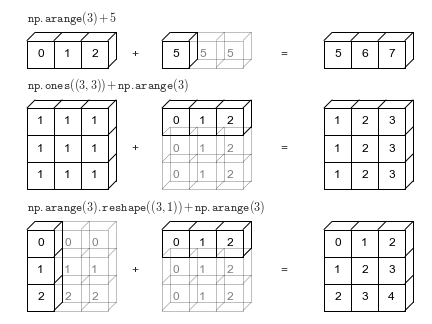
Broadcasting only works if one of the arrays can be replicated to match the other array's shape.

In [126]:
arr5 = np.array([7])
arr5.shape

(1,)

In [127]:
arr2 + arr5

array([[ 8,  9, 10, 11],
       [12, 13, 14, 15],
       [16,  8,  9, 10]])

n the above example, even if arr5 is replicated three times, it will not match the shape of arr2. Hence arr2 + arr5 cannot be evaluated successfully. Learn more about broadcasting here: https://numpy.org/doc/stable/user/basics.broadcasting.html .

In [128]:
arr5

array([7])

#### Array Comparison
Numpy arrays also support comparison operations like ==, !=, > etc. The result is an array of booleans.

In [ ]:
arr1 = np.array([[1, 2, 3], 
                 [3, 4, 5]])

arr2 = np.array([[2, 2, 3], 
                 [1, 2, 5]])

In [131]:
arr1 == arr2

array([[False,  True,  True],
       [False, False,  True]])

In [132]:
arr1 >= arr2

array([[False,  True,  True],
       [ True,  True,  True]])

In [133]:
arr1 > arr2

array([[False, False, False],
       [ True,  True, False]])

In [134]:
arr1 <= arr2

array([[ True,  True,  True],
       [False, False,  True]])

In [135]:
arr1 < arr2

array([[ True, False, False],
       [False, False, False]])

In [136]:
arr1 != arr2

array([[ True, False, False],
       [ True,  True, False]])

Array comparison is frequently used to count the number of equal elements in two arrays using the sum method. Remember that True evaluates to 1 and False evaluates to 0 when booleans are used in arithmetic operations.

In [143]:
(arr1 == arr2).sum() ##number of equal elements in arr1 and arr2

np.int64(3)

In [163]:
array = np.array(range(10))
array= array.reshape(10, 1)
print(array)

[[0]
 [1]
 [2]
 [3]
 [4]
 [5]
 [6]
 [7]
 [8]
 [9]]


##### Array indexing and slicing
Numpy extends Python's list indexing notation using [] to multiple dimensions in an intuitive fashion. You can provide a comma-separated list of indices or ranges to select a specific element or a subarray (also called a slice) from a Numpy array.

In [139]:
arr3 = np.array([
    [[11, 12, 13, 14],  [13, 14, 15, 19]], 
    
    [[15, 16, 17, 21],  [63, 92, 36, 18]], 
    
    [[98, 32, 81, 23],  [17, 18, 19.5, 43]]])

In [168]:
arr3[1, 1, 2] 
#### like coordinate sustem  ### zero based indexing ####sim=ngle element

np.float64(36.0)

In [165]:
arr3

array([[[11. , 12. , 13. , 14. ],
        [13. , 14. , 15. , 19. ]],

       [[15. , 16. , 17. , 21. ],
        [63. , 92. , 36. , 18. ]],

       [[98. , 32. , 81. , 23. ],
        [17. , 18. , 19.5, 43. ]]])

In [170]:
arr3[1:]

array([[[15. , 16. , 17. , 21. ],
        [63. , 92. , 36. , 18. ]],

       [[98. , 32. , 81. , 23. ],
        [17. , 18. , 19.5, 43. ]]])

In [173]:
arr3[1:, 0:1, 2:]

array([[[17., 21.]],

       [[81., 23.]]])

In [ ]:
# Subarray using ranges
arr3[1:, 0:1, :2] ##the end of the range is not considered for
                    #range 1:3 it means it takes value from 1 to 2
                    #only not 3 remembr fs

array([[[15., 16.]],

       [[98., 32.]]])

In [176]:
arr3[1:, 1, :3]

array([[63. , 92. , 36. ],
       [17. , 18. , 19.5]])

In [177]:
arr3[1]

array([[15., 16., 17., 21.],
       [63., 92., 36., 18.]])

##### Other ways of creating Numpy array
Numpy also provides some handy functions to create arrays of desired shapes with fixed or random values. Check out the official documentation or use the help function to learn more.

In [179]:
np.zeros((3, 2))

array([[0., 0.],
       [0., 0.],
       [0., 0.]])

In [181]:
np.ones((3, 2, 5))

array([[[1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.]],

       [[1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.]],

       [[1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.]]])

In [182]:
np.eye(3) #to make a identity matrix

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [187]:
np.random.rand(5, 2) # random vector picts from values from 0 to 1

array([[0.15998981, 0.22149279],
       [0.60827286, 0.76995771],
       [0.40778659, 0.33208061],
       [0.07393123, 0.45245755],
       [0.33993786, 0.88443136]])

In [186]:
np.random.randn(2, 3) # random matrix wide range but most around zero

array([[-1.33424949,  1.08886789,  0.30984533],
       [-0.61969164,  2.29527781, -1.53319105]])

In [190]:
np.full([2, 3], 42) #fixed value same element matrix

array([[42, 42, 42],
       [42, 42, 42]])

In [ ]:
np.arange(10, 90, 3) #np.arange(start, stop, steps of 3(by what value it must increase))

array([10, 13, 16, 19, 22, 25, 28, 31, 34, 37, 40, 43, 46, 49, 52, 55, 58,
       61, 64, 67, 70, 73, 76, 79, 82, 85, 88])

In [202]:
np.arange(10, 90, 3).reshape(3, 3, 3)

array([[[10, 13, 16],
        [19, 22, 25],
        [28, 31, 34]],

       [[37, 40, 43],
        [46, 49, 52],
        [55, 58, 61]],

       [[64, 67, 70],
        [73, 76, 79],
        [82, 85, 88]]])

In [209]:
np.linspace(3, 27, 9) ## it take start, end and how many equally spaced vlues do we need

array([ 3.,  6.,  9., 12., 15., 18., 21., 24., 27.])

In [212]:
import urllib.request
urllib.request.urlretrieve(
    ' https://github.com/rougier/numpy-100', 
    'numpy-100.ipynb')

('numpy-100.ipynb', <http.client.HTTPMessage at 0x2237f63b980>)

<module 'numpy.version' from 'c:\\Users\\Akhil Kiriti Gentela\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\numpy\\version.py'>